In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Flight Delay Analysis and Prediction")
print("Libraries imported successfully!")

Flight Delay Analysis and Prediction
Libraries imported successfully!


In [2]:
data_path = Path("data/processed/cleaned_flights.csv")

df = pd.read_csv(data_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1671127, 19)


,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY_NEW,CRS_ARR_TIME,ARR_DELAY_NEW,ARR_DEL15,CANCELLED,DIVERTED,DISTANCE,ScheduledDepHour,ScheduledArrHour,DayOfWeek,Month,MonthLabel
0,1,1,2026-01-01,AA,ABQ,DFW,600,0.0,902,0.0,0.0,0.0,0.0,569.0,6,9,3,1,Jan 2026
1,1,1,2026-01-01,AA,ABQ,DFW,819,0.0,1121,0.0,0.0,0.0,0.0,569.0,8,11,3,1,Jan 2026
2,1,1,2026-01-01,AA,ABQ,DFW,1030,2036.0,1330,2021.0,1.0,0.0,0.0,569.0,10,13,3,1,Jan 2026
3,1,1,2026-01-01,AA,ABQ,DFW,1238,0.0,1538,0.0,0.0,0.0,0.0,569.0,12,15,3,1,Jan 2026
4,1,1,2026-01-01,AA,ABQ,DFW,1656,114.0,2000,86.0,1.0,0.0,0.0,569.0,16,20,3,1,Jan 2026


In [3]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check the number of missing values
print("\nMissing Values:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0].sort_values(ascending=False))

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Column Names:
['MONTH', 'DAY_OF_MONTH', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_DELAY_NEW', 'CRS_ARR_TIME', 'ARR_DELAY_NEW', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'ScheduledDepHour', 'ScheduledArrHour', 'DayOfWeek', 'Month', 'MonthLabel']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1671127 entries, 0 to 1671126
Data columns (total 19 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   MONTH              1671127 non-null  int64  
 1   DAY_OF_MONTH       1671127 non-null  int64  
 2   FL_DATE            1671127 non-null  str    
 3   OP_UNIQUE_CARRIER  1671127 non-null  str    
 4   ORIGIN             1671127 non-null  str    
 5   DEST               1671127 non-null  str    
 6   CRS_DEP_TIME       1671127 non-null  int64  
 7   DEP_DELAY_NEW      1617323 non-null  float64
 8   CRS_ARR_TIME       1671127 non-null  int64  
 9   ARR_DELAY_NEW      1611862 non-null  fl

ARR_DELAY_NEW    59265
ARR_DEL15        59265
DEP_DELAY_NEW    53804
dtype: int64


Duplicate Records: 0


In [4]:
# Count delayed and non-delayed flights
delay_counts = df["ARR_DEL15"].value_counts(dropna=False).sort_index()

print("Arrival Delay Distribution:")
display(delay_counts.rename(index={
    0: "Not Delayed",
    1: "Delayed (15+ minutes)"
}).to_frame("Number of Flights"))

# Calculate delay percentage using eligible records
eligible_flights = df["ARR_DEL15"].dropna()

delay_rate = (eligible_flights == 1).mean() * 100

print(f"Eligible flights: {len(eligible_flights):,}")
print(f"Arrival delay rate: {delay_rate:.2f}%")

Arrival Delay Distribution:


,Number of Flights
ARR_DEL15,
Not Delayed,1261105
Delayed (15+ minutes),350757
NaN,59265


Eligible flights: 1,611,862
Arrival delay rate: 21.76%


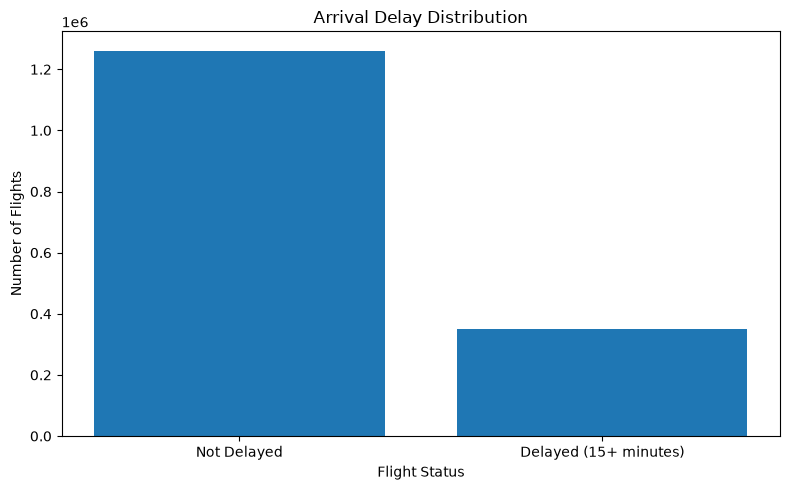

In [5]:
# Arrival Delay Distribution

delay_counts = df["ARR_DEL15"].dropna().value_counts().sort_index()

labels = ["Not Delayed", "Delayed (15+ minutes)"]
values = [
    delay_counts.get(0, 0),
    delay_counts.get(1, 0)
]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)
plt.title("Arrival Delay Distribution")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

Monthly Arrival Delay Rate (%)


,Delay Rate (%)
MONTH,
1,20.78
2,19.76
3,24.32


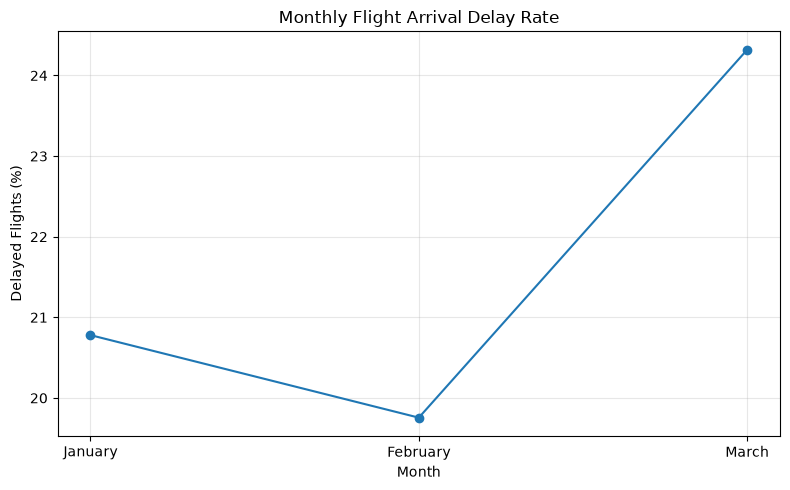

In [6]:
# Monthly Arrival Delay Rate

monthly_delay = (
    df.dropna(subset=["ARR_DEL15"])
      .groupby("MONTH")["ARR_DEL15"]
      .mean()
      .mul(100)
)

print("Monthly Arrival Delay Rate (%)")
display(monthly_delay.round(2).to_frame("Delay Rate (%)"))

plt.figure(figsize=(8, 5))
plt.plot(monthly_delay.index, monthly_delay.values, marker="o")
plt.title("Monthly Flight Arrival Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")
plt.xticks([1, 2, 3], ["January", "February", "March"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Airline-wise Arrival Delay Statistics:


,Total_Flights,Delayed_Flights,Delay_Rate
OP_UNIQUE_CARRIER,,,
NK,33201,11761.0,35.42
B6,54157,16901.0,31.21
F9,49070,13128.0,26.75
OH,53306,14258.0,26.75
G4,29985,7475.0,24.93
AA,223353,52636.0,23.57
YX,82403,18728.0,22.73
OO,195400,43695.0,22.36
AS,76637,15426.0,20.13


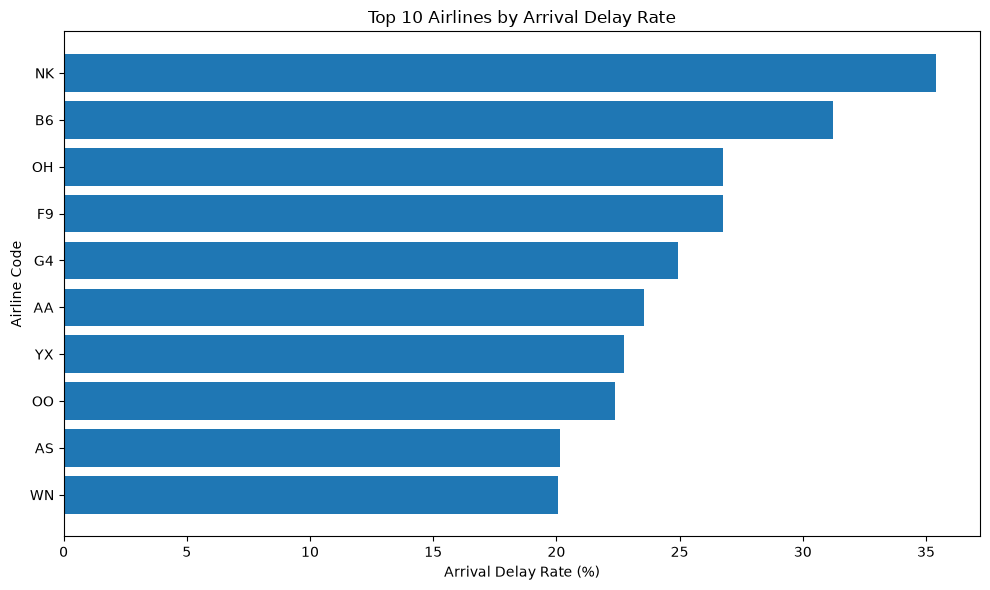

In [7]:
# Airline-wise Arrival Delay Analysis

airline_delay = (
    df.dropna(subset=["ARR_DEL15"])
      .groupby("OP_UNIQUE_CARRIER")
      .agg(
          Total_Flights=("ARR_DEL15", "count"),
          Delayed_Flights=("ARR_DEL15", "sum"),
          Delay_Rate=("ARR_DEL15", "mean")
      )
)

airline_delay["Delay_Rate"] = (
    airline_delay["Delay_Rate"] * 100
).round(2)

airline_delay = airline_delay.sort_values(
    "Delay_Rate", ascending=False
)

print("Airline-wise Arrival Delay Statistics:")
display(airline_delay)

# Visualize the 10 airlines with the highest delay rates
top_airlines = airline_delay.head(10).sort_values("Delay_Rate")

plt.figure(figsize=(10, 6))
plt.barh(top_airlines.index, top_airlines["Delay_Rate"])
plt.title("Top 10 Airlines by Arrival Delay Rate")
plt.xlabel("Arrival Delay Rate (%)")
plt.ylabel("Airline Code")
plt.tight_layout()
plt.show()

Top 10 Departure Airports by Arrival Delay Rate:


,Total_Flights,Delayed_Flights,Delay_Rate
ORIGIN,,,
PBG,124,59.0,47.58
ORH,212,91.0,42.92
CMX,157,64.0,40.76
EAU,144,57.0,39.58
MQT,278,108.0,38.85
BET,169,65.0,38.46
JST,163,62.0,38.04
TOL,152,57.0,37.50
USA,145,54.0,37.24


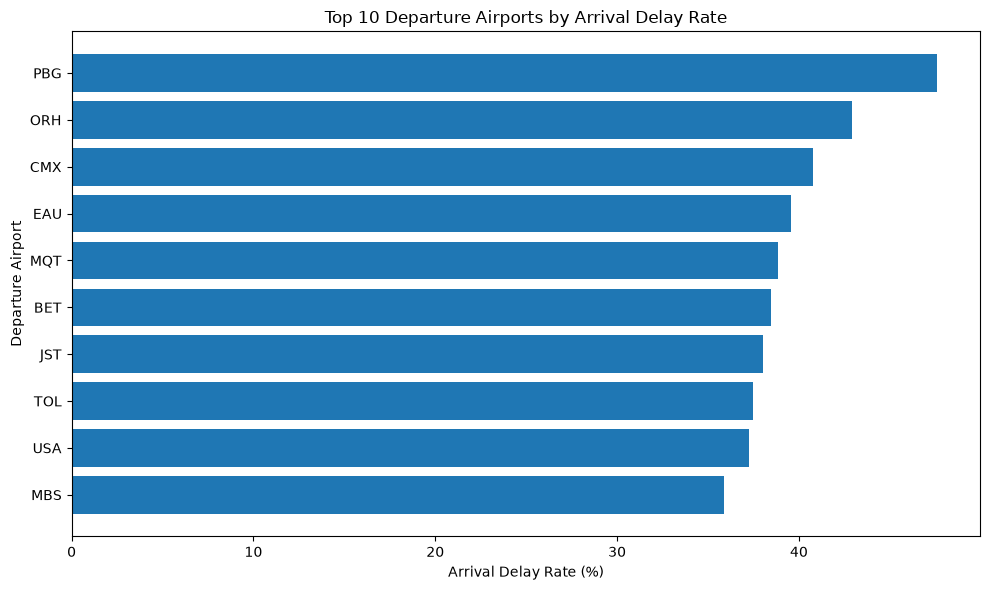

In [8]:
# Airport-wise Arrival Delay Analysis

# Analyze departure airports
origin_analysis = (
    df.dropna(subset=["ARR_DEL15"])
      .groupby("ORIGIN")
      .agg(
          Total_Flights=("ARR_DEL15", "count"),
          Delayed_Flights=("ARR_DEL15", "sum"),
          Delay_Rate=("ARR_DEL15", "mean")
      )
)

origin_analysis["Delay_Rate"] = (
    origin_analysis["Delay_Rate"] * 100
).round(2)

# Show airports with at least 100 eligible flights
origin_analysis = origin_analysis[
    origin_analysis["Total_Flights"] >= 100
].sort_values("Delay_Rate", ascending=False)

print("Top 10 Departure Airports by Arrival Delay Rate:")
display(origin_analysis.head(10))

# Plot the results
top_airports = origin_analysis.head(10).sort_values("Delay_Rate")

plt.figure(figsize=(10, 6))
plt.barh(top_airports.index, top_airports["Delay_Rate"])
plt.title("Top 10 Departure Airports by Arrival Delay Rate")
plt.xlabel("Arrival Delay Rate (%)")
plt.ylabel("Departure Airport")
plt.tight_layout()
plt.show()

Arrival Delay Rate by Scheduled Departure Hour:


,Eligible Flights,Delay Rate (%)
DEP_HOUR,,
0,2178,14.10
1,882,21.43
2,376,24.47
3,148,21.62
4,45,15.56
5,43357,9.88
6,108935,11.70
7,119105,14.07
8,112094,16.07


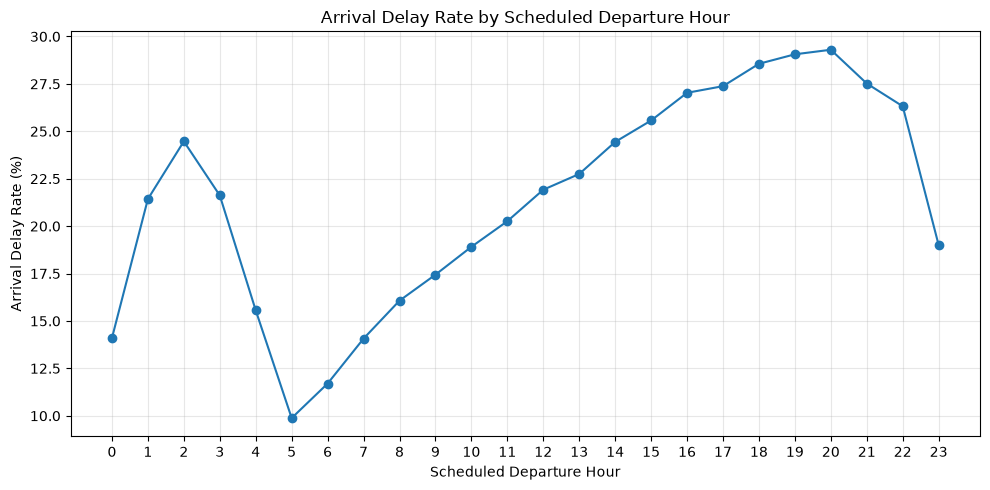

In [9]:
# Departure-Time Delay Analysis

# Keep valid scheduled departure times
time_df = df.dropna(subset=["CRS_DEP_TIME", "ARR_DEL15"]).copy()

# Convert HHMM scheduled times into departure hours
time_df["DEP_HOUR"] = (
    time_df["CRS_DEP_TIME"].astype(int) // 100
)

# Keep valid hours from 0 to 23
time_df = time_df[time_df["DEP_HOUR"].between(0, 23)]

hourly_delay = (
    time_df.groupby("DEP_HOUR")["ARR_DEL15"]
           .agg(["count", "mean"])
)

hourly_delay["Delay_Rate"] = (
    hourly_delay["mean"] * 100
).round(2)

print("Arrival Delay Rate by Scheduled Departure Hour:")
display(hourly_delay[["count", "Delay_Rate"]].rename(
    columns={
        "count": "Eligible Flights",
        "Delay_Rate": "Delay Rate (%)"
    }
))

plt.figure(figsize=(10, 5))
plt.plot(
    hourly_delay.index,
    hourly_delay["Delay_Rate"],
    marker="o"
)
plt.title("Arrival Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Arrival Delay Rate (%)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.57112,0.314275,0.650771,0.423858,0.637089
1,Logistic Regression,0.62151,0.325242,0.522317,0.400867,0.623752


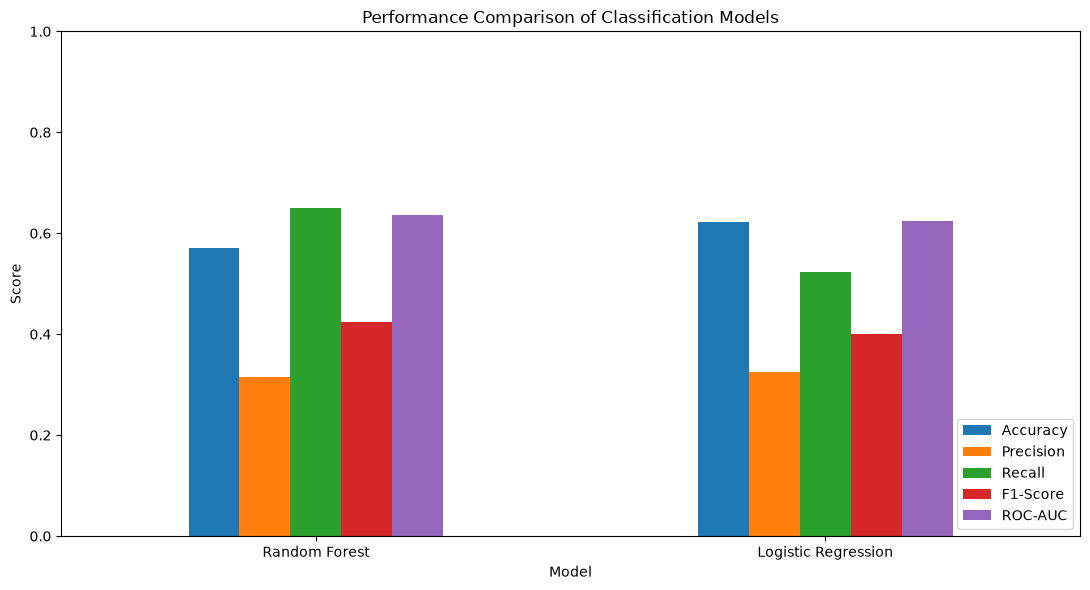

In [11]:
# Model Performance Comparison

results_path = Path("reports/model_comparison.csv")

if results_path.exists() and results_path.stat().st_size > 0:
    model_results = pd.read_csv(results_path)
else:
    model_results = pd.DataFrame()

# Standardize column names
model_results.columns = (
    model_results.columns.str.strip().str.lower()
    .str.replace("-", "_", regex=False)
    .str.replace(" ", "_", regex=False)
)

# Use recorded results if the CSV doesn't contain the expected metrics
required = {
    "accuracy", "precision", "recall", "f1_score", "roc_auc"
}

if not required.issubset(set(model_results.columns)):
    model_results = pd.DataFrame({
        "Model": ["Logistic Regression", "Random Forest"],
        "Accuracy": [0.6215, 0.5711],
        "Precision": [0.3252, 0.3143],
        "Recall": [0.5223, 0.6508],
        "F1-Score": [0.4009, 0.4239],
        "ROC-AUC": [0.6238, 0.6371]
    })

# Standardize display names for plotting
model_results = model_results.rename(columns={
    "model": "Model",
    "f1_score": "F1-Score",
    "roc_auc": "ROC-AUC",
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall"
})

metrics = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

print("Model Performance Comparison:")
display(model_results)

model_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
# Check available project reports

reports_path = Path("reports")

print("Available report files:")
for file in sorted(reports_path.glob("*.csv")):
    print("-", file.name)

Available report files:
- airline_analysis.csv
- airport_analysis.csv
- hourly_analysis.csv
- missing_values.csv
- model_comparison.csv
- monthly_analysis.csv
- route_analysis.csv


## Conclusion

This project analyzed U.S. flight records from January to March 2026 to identify arrival-delay patterns across months, airlines, airports, and departure schedules.

The analysis found that **21.76% of eligible flights experienced arrival delays of 15 minutes or more**. March had the highest monthly arrival-delay rate at 24.32%, compared with 20.78% in January and 19.76% in February.

Logistic Regression and Random Forest were evaluated for predicting arrival delays. Random Forest achieved a higher recall (0.6508) and F1-score (0.4239), while Logistic Regression achieved higher accuracy (0.6215).

Overall, this project demonstrates how data cleaning, exploratory data analysis, visualization, feature preparation, and classification algorithms can be used to understand flight delays and predict potential disruptions. The results can help identify delay patterns and support better flight planning.